In [1]:

import sys
import platform

print("¡Proyecto EDA UTEC iniciado correctamente!")
print("Versión de Python:", sys.version.split()[0])
print("Sistema operativo:", platform.system())
print("Entorno:", sys.executable)


¡Proyecto EDA UTEC iniciado correctamente!
Versión de Python: 3.12.10
Sistema operativo: Windows
Entorno: c:\Users\bryan\Proyecto_EDA_UTEC\.venv\Scripts\python.exe


In [1]:

import numpy as np
import pandas as pd
import matplotlib
import pyarrow
import duckdb
import psutil

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("PyArrow:", pyarrow.__version__)
print("DuckDB:", duckdb.__version__)
print("psutil:", psutil.__version__)

print("\n¡Librerías instaladas correctamente!")


NumPy: 2.5.4
Pandas: 3.1.0
Matplotlib: 3.11.2
PyArrow: 26.0.0
DuckDB: 2.0.0
psutil: 7.2.2

¡Librerías instaladas correctamente!


## Verificar el archivo desde Jupyter

In [2]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "raw" / "2019-Oct.csv"

print("Ruta:", DATA_PATH)
print("Archivo encontrado:", DATA_PATH.exists())

if DATA_PATH.exists():
    size_gb = DATA_PATH.stat().st_size / (1024**3)
    print(f"Tamaño: {size_gb:.2f} GiB")


Ruta: c:\Users\bryan\Proyecto_EDA_UTEC\data\raw\2019-Oct.csv
Archivo encontrado: True
Tamaño: 5.28 GiB


## Exploración inicial del dataset REES46

In [3]:

import pandas as pd
import time

# Tamaño inicial de la muestra
N_SAMPLE = 100_000

# Medir el tiempo de lectura
inicio = time.perf_counter()

df_sample = pd.read_csv(
    DATA_PATH,
    nrows=N_SAMPLE
)

tiempo = time.perf_counter() - inicio

print(f"Registros cargados: {len(df_sample):,}")
print(f"Tiempo de lectura: {tiempo:.3f} segundos")
print(f"Columnas: {df_sample.shape[1]}")
print(
    f"Memoria utilizada: "
    f"{df_sample.memory_usage(deep=True).sum() / 1024**2:.2f} MiB"
)

display(df_sample.head(10))


Registros cargados: 100,000
Tiempo de lectura: 0.237 segundos
Columnas: 9
Memoria utilizada: 14.85 MiB


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d
5,2019-10-01 00:00:05 UTC,view,1480613,2053013561092866779,computers.desktop,pulser,908.62,512742880,0d0d91c2-c9c2-4e81-90a5-86594dec0db9
6,2019-10-01 00:00:08 UTC,view,17300353,2053013553853497655,NaN,creed,380.96,555447699,4fe811e9-91de-46da-90c3-bbd87ed3a65d
7,2019-10-01 00:00:08 UTC,view,31500053,2053013558031024687,NaN,luminarc,41.16,550978835,6280d577-25c8-4147-99a7-abc6048498d6
8,2019-10-01 00:00:10 UTC,view,28719074,2053013565480109009,apparel.shoes.keds,baden,102.71,520571932,ac1cd4e5-a3ce-4224-a2d7-ff660a105880
9,2019-10-01 00:00:11 UTC,view,1004545,2053013555631882655,electronics.smartphone,huawei,566.01,537918940,406c46ed-90a4-4787-a43b-59a410c1a5fb


In [4]:

print("=== INFORMACIÓN GENERAL ===")
df_sample.info()

print("\n=== TIPOS DE EVENTOS ===")
print(df_sample["event_type"].value_counts())

print("\n=== VALORES NULOS ===")
display(
    df_sample.isnull().sum()
    .to_frame("valores_nulos")
)

print("\n=== REGISTROS DUPLICADOS EXACTOS ===")
print(df_sample.duplicated().sum())


=== INFORMACIÓN GENERAL ===
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     100000 non-null  str    
 1   event_type     100000 non-null  str    
 2   product_id     100000 non-null  int64  
 3   category_id    100000 non-null  int64  
 4   category_code  67413 non-null   str    
 5   brand          85607 non-null   str    
 6   price          100000 non-null  float64
 7   user_id        100000 non-null  int64  
 8   user_session   100000 non-null  str    
dtypes: float64(1), int64(3), str(5)
memory usage: 14.9 MB

=== TIPOS DE EVENTOS ===
event_type
view        97130
purchase     1655
cart         1215
Name: count, dtype: int64

=== VALORES NULOS ===


,valores_nulos
event_time,0
event_type,0
product_id,0
category_id,0
category_code,32587
brand,14393
price,0
user_id,0
user_session,0



=== REGISTROS DUPLICADOS EXACTOS ===
17


## Analizar usuarios, productos y sesiones

In [5]:

# Análisis de entidades y relaciones del dataset

print("=== ENTIDADES ÚNICAS ===")
print(f"Usuarios únicos: {df_sample['user_id'].nunique():,}")
print(f"Productos únicos: {df_sample['product_id'].nunique():,}")
print(f"Sesiones únicas: {df_sample['user_session'].nunique():,}")
print(f"Categorías únicas: {df_sample['category_id'].nunique():,}")

print("\n=== EVENTOS POR USUARIO ===")
eventos_usuario = df_sample.groupby("user_id").size()

print(f"Promedio: {eventos_usuario.mean():.2f}")
print(f"Mediana: {eventos_usuario.median():.2f}")
print(f"Máximo: {eventos_usuario.max():,}")

print("\n=== PRODUCTOS MÁS VISUALIZADOS ===")
top_views = (
    df_sample[df_sample["event_type"] == "view"]
    .groupby("product_id")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

display(top_views.to_frame("visualizaciones"))

print("\n=== SESIONES CON MÚLTIPLES PRODUCTOS COMPRADOS ===")

compras = df_sample[df_sample["event_type"] == "purchase"]

productos_por_sesion = (
    compras.groupby("user_session")["product_id"]
    .nunique()
)

sesiones_multiproducto = (productos_por_sesion >= 2).sum()

print(f"Total de sesiones con compras: {len(productos_por_sesion):,}")
print(f"Sesiones con 2+ productos distintos: {sesiones_multiproducto:,}")
print(f"Máximo de productos distintos: {productos_por_sesion.max() if len(productos_por_sesion) else 0}")


=== ENTIDADES ÚNICAS ===
Usuarios únicos: 20,384
Productos únicos: 20,621
Sesiones únicas: 24,382
Categorías únicas: 509

=== EVENTOS POR USUARIO ===
Promedio: 4.91
Mediana: 3.00
Máximo: 130

=== PRODUCTOS MÁS VISUALIZADOS ===


,visualizaciones
product_id,
1004856,994
1005115,920
1004767,793
1005105,547
1004870,546
1004833,455
1004249,448
5100816,421
1002544,395



=== SESIONES CON MÚLTIPLES PRODUCTOS COMPRADOS ===
Total de sesiones con compras: 1,431
Sesiones con 2+ productos distintos: 86
Máximo de productos distintos: 7


## Definir el esquema de eventos del pipeline

### 4. Normalización inicial de eventos

In [6]:

import pandas as pd
import numpy as np

# Copia de trabajo: preservamos la muestra original
df_events = df_sample.copy()

# ID estable para las filas originales de esta muestra
df_events.insert(
    0,
    "event_id",
    np.arange(len(df_events), dtype=np.int64)
)

# Conversión de timestamp a UTC
df_events["event_timestamp"] = pd.to_datetime(
    df_events["event_time"],
    utc=True,
    errors="coerce"
)

# Validación inicial
print("=== VALIDACIÓN ===")
print("Eventos:", len(df_events))
print("IDs únicos:", df_events["event_id"].is_unique)
print(
    "Timestamps inválidos:",
    df_events["event_timestamp"].isna().sum()
)

print("\n=== TIPOS DE DATOS ===")
print(df_events.dtypes)

print("\n=== MUESTRA NORMALIZADA ===")
display(df_events.head(5))


=== VALIDACIÓN ===
Eventos: 100000
IDs únicos: True
Timestamps inválidos: 0

=== TIPOS DE DATOS ===
event_id                         int64
event_time                         str
event_type                         str
product_id                       int64
category_id                      int64
category_code                      str
brand                              str
price                          float64
user_id                          int64
user_session                       str
event_timestamp    datetime64[us, UTC]
dtype: object

=== MUESTRA NORMALIZADA ===


,event_id,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,event_timestamp
0,0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00
1,1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00
2,2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00
3,3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00
4,4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00


# Etapa 0. Ingesta y buffer FIFO

## 5. Etapa 0: Prueba de ingesta FIFO

In [7]:

import sys

# Permitir importar módulos de la carpeta src
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.ingestion import EventBufferFIFO

# Crear buffer
buffer = EventBufferFIFO()

# Seleccionar los primeros 5 eventos reales
eventos_prueba = df_events.head(5).to_dict("records")

# Encolar eventos
for evento in eventos_prueba:
    buffer.enqueue(evento)

print("=== INGESTA ===")
print("Eventos recibidos:", buffer.total_received)
print("Eventos pendientes:", len(buffer))

# Procesar eventos
print("\n=== PROCESAMIENTO FIFO ===")

while not buffer.is_empty():
    evento = buffer.dequeue()

    print(
        f"Evento {evento['event_id']} | "
        f"Tipo: {evento['event_type']} | "
        f"Producto: {evento['product_id']}"
    )

print("\n=== RESULTADOS ===")
print("Eventos procesados:", buffer.total_processed)
print("Eventos pendientes:", len(buffer))


=== INGESTA ===
Eventos recibidos: 5
Eventos pendientes: 5

=== PROCESAMIENTO FIFO ===
Evento 0 | Tipo: view | Producto: 44600062
Evento 1 | Tipo: view | Producto: 3900821
Evento 2 | Tipo: view | Producto: 17200506
Evento 3 | Tipo: view | Producto: 1307067
Evento 4 | Tipo: view | Producto: 1004237

=== RESULTADOS ===
Eventos procesados: 5
Eventos pendientes: 0


## Procesamiento FIFO con 100,000 eventos

In [9]:

import time
import tracemalloc

# Preparar eventos
eventos = df_events.to_dict("records")

# Crear una nueva cola
buffer_100k = EventBufferFIFO()

# Iniciar medición
tracemalloc.start()
inicio = time.perf_counter()

# Ingesta
for evento in eventos:
    buffer_100k.enqueue(evento)

tiempo_ingesta = time.perf_counter() - inicio

# Procesamiento
inicio_proceso = time.perf_counter()

primer_id = None
ultimo_id = None

while not buffer_100k.is_empty():
    evento = buffer_100k.dequeue()

    if primer_id is None:
        primer_id = evento["event_id"]

    ultimo_id = evento["event_id"]

tiempo_proceso = time.perf_counter() - inicio_proceso

memoria_actual, memoria_pico = tracemalloc.get_traced_memory()
tracemalloc.stop()

print("=== RESULTADOS FIFO 100K ===")
print(f"Eventos recibidos: {buffer_100k.total_received:,}")
print(f"Eventos procesados: {buffer_100k.total_processed:,}")
print(f"Pendientes: {len(buffer_100k):,}")

print(f"\nPrimer ID: {primer_id}")
print(f"Último ID: {ultimo_id}")

print(f"\nTiempo de ingesta: {tiempo_ingesta:.4f} s")
print(f"Tiempo de procesamiento: {tiempo_proceso:.4f} s")
print(f"Tiempo total: {tiempo_ingesta + tiempo_proceso:.4f} s")

print(f"\nMemoria pico medida: {memoria_pico / 1024**2:.2f} MiB")


=== RESULTADOS FIFO 100K ===
Eventos recibidos: 100,000
Eventos procesados: 100,000
Pendientes: 0

Primer ID: 0
Último ID: 99999

Tiempo de ingesta: 0.0494 s
Tiempo de procesamiento: 0.0930 s
Tiempo total: 0.1424 s

Memoria pico medida: 0.81 MiB


## 7. Etapa 1: Preprocesamiento y deduplicación

In [10]:

from src.preprocessing import preprocess_batch

# Tomamos 10 eventos reales de REES46
eventos_originales = df_events.head(10).to_dict("records")

# Simulamos dos retransmisiones del mismo evento
eventos_prueba = (
    eventos_originales
    + [eventos_originales[2].copy()]
    + [eventos_originales[5].copy()]
)

print("=== ANTES DEL PREPROCESAMIENTO ===")
print("Eventos recibidos:", len(eventos_prueba))

# Ejecutamos la Etapa 1
resultado = preprocess_batch(eventos_prueba)

print("\n=== DESPUÉS DEL PREPROCESAMIENTO ===")
print("Eventos válidos:", resultado["valid"])
print("Eventos inválidos:", resultado["invalid"])
print("Duplicados técnicos:", resultado["duplicates"])
print("Eventos finales:", len(resultado["events"]))

print("\n=== IDs PROCESADOS ===")
print([event["event_id"] for event in resultado["events"]])


=== ANTES DEL PREPROCESAMIENTO ===
Eventos recibidos: 12

=== DESPUÉS DEL PREPROCESAMIENTO ===
Eventos válidos: 12
Eventos inválidos: 0
Duplicados técnicos: 2
Eventos finales: 10

=== IDs PROCESADOS ===
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 8. Integración de etapas 0 y 1

In [11]:

from src.pipeline import run_ingestion_pipeline

# Utilizamos los 100 000 eventos normalizados
eventos_pipeline = df_events.to_dict("records")

resultado_pipeline = run_ingestion_pipeline(
    events=eventos_pipeline,
    batch_size=5000
)

print("=== PIPELINE ETAPAS 0 Y 1 ===")

for clave, valor in resultado_pipeline["metrics"].items():
    print(f"{clave}: {valor:,}")

print("\n=== VERIFICACIONES ===")

ids = [
    evento["event_id"]
    for evento in resultado_pipeline["events"]
]

print("Total de IDs:", len(ids))
print("IDs únicos:", len(ids) == len(set(ids)))
print("Primer ID:", ids[0])
print("Último ID:", ids[-1])


=== PIPELINE ETAPAS 0 Y 1 ===
received: 100,000
valid: 100,000
invalid: 0
duplicates: 0
output: 100,000

=== VERIFICACIONES ===
Total de IDs: 100000
IDs únicos: True
Primer ID: 0
Último ID: 99999


## 9. Etapa 2: Priorización de eventos mediante Heap

In [15]:

from src.priority_queue import EventPriorityQueue, EVENT_PRIORITIES

# Elegimos eventos reales de los tres tipos
view_event = df_events[
    df_events["event_type"] == "view"
].iloc[0].to_dict()

cart_event = df_events[
    df_events["event_type"] == "cart"
].iloc[0].to_dict()

purchase_event = df_events[
    df_events["event_type"] == "purchase"
].iloc[0].to_dict()

# Simulamos una alerta crítica sobre una copia
critical_event = view_event.copy()
critical_event["event_id"] = 999999
critical_event["is_critical_alert"] = True

# Encolar en un orden intencionalmente distinto
events = [
    view_event,
    cart_event,
    purchase_event,
    critical_event
]

priority_queue = EventPriorityQueue()

for event in events:
    priority_queue.enqueue(event)

print("=== ORDEN DE LLEGADA ===")
print([event["event_type"] for event in events])

print("\n=== ORDEN DE PROCESAMIENTO ===")

while not priority_queue.is_empty():
    event = priority_queue.dequeue()

    priority = (
        0 if event.get("is_critical_alert", False)
        else EVENT_PRIORITIES[event["event_type"]]
    )

    print(
        f"Prioridad: {priority} | "
        f"Evento: {event['event_type']} | "
        f"ID: {event['event_id']}"
    )

print("\n=== MÉTRICAS ===")
print("Recibidos:", priority_queue.total_received)
print("Procesados:", priority_queue.total_processed)
print("Pendientes:", len(priority_queue))


=== ORDEN DE LLEGADA ===
['view', 'cart', 'purchase', 'view']

=== ORDEN DE PROCESAMIENTO ===
Prioridad: 0 | Evento: view | ID: 999999
Prioridad: 1 | Evento: purchase | ID: 162
Prioridad: 2 | Evento: cart | ID: 331
Prioridad: 3 | Evento: view | ID: 0

=== MÉTRICAS ===
Recibidos: 4
Procesados: 4
Pendientes: 0


## 10. Integración de etapas 0, 1 y 2

In [27]:

import importlib
import src.pipeline

# Recargar el módulo después de modificar pipeline.py
importlib.reload(src.pipeline)

# Importar la nueva función
from src.pipeline import run_priority_pipeline

print("¡Función importada correctamente!")


¡Función importada correctamente!


In [20]:
from src.pipeline import run_priority_pipeline

# Utilizamos una muestra inicial de 1000 eventos
eventos_1k = df_events.head(1000).to_dict("records")

resultado_3_etapas = run_priority_pipeline(
    events=eventos_1k,
    batch_size=200
)

print("=== PIPELINE ETAPAS 0, 1 Y 2 ===")

for clave, valor in resultado_3_etapas["metrics"].items():
    print(f"{clave}: {valor:,}")

print("\n=== DISTRIBUCIÓN DE EVENTOS ===")

tipos = [
    event["event_type"]
    for event in resultado_3_etapas["events"]
]

print(pd.Series(tipos).value_counts())

print("\n=== PRIMEROS 15 EVENTOS PROCESADOS ===")

for event in resultado_3_etapas["events"][:15]:
    print(
        f"ID: {event['event_id']} | "
        f"Tipo: {event['event_type']}"
    )


=== PIPELINE ETAPAS 0, 1 Y 2 ===
received: 1,000
valid: 1,000
invalid: 0
duplicates: 0
output: 1,000
priority_received: 1,000
priority_processed: 1,000

=== DISTRIBUCIÓN DE EVENTOS ===
view        987
purchase     10
cart          3
Name: count, dtype: int64

=== PRIMEROS 15 EVENTOS PROCESADOS ===
ID: 162 | Tipo: purchase
ID: 308 | Tipo: purchase
ID: 379 | Tipo: purchase
ID: 442 | Tipo: purchase
ID: 574 | Tipo: purchase
ID: 603 | Tipo: purchase
ID: 618 | Tipo: purchase
ID: 672 | Tipo: purchase
ID: 749 | Tipo: purchase
ID: 860 | Tipo: purchase
ID: 331 | Tipo: cart
ID: 583 | Tipo: cart
ID: 680 | Tipo: cart
ID: 0 | Tipo: view
ID: 1 | Tipo: view


In [21]:

from src.priority_queue import EVENT_PRIORITIES

events = resultado_3_etapas["events"]

prioridades = [
    EVENT_PRIORITIES[event["event_type"]]
    for event in events
]

orden_correcto = all(
    prioridades[i] <= prioridades[i + 1]
    for i in range(len(prioridades) - 1)
)

print("=== VALIDACIÓN FINAL ETAPAS 0-2 ===")
print("Total de eventos:", len(events))
print("Orden de prioridad correcto:", orden_correcto)
print("Primera prioridad:", prioridades[0])
print("Última prioridad:", prioridades[-1])

assert len(events) == 1000
assert orden_correcto

# Verificar conservación de todos los IDs originales
ids_originales = {
    event["event_id"]
    for event in eventos_1k
}

ids_procesados = {
    event["event_id"]
    for event in events
}

assert ids_originales == ids_procesados

print("\n¡Las tres etapas están integradas correctamente!")


=== VALIDACIÓN FINAL ETAPAS 0-2 ===
Total de eventos: 1000
Orden de prioridad correcto: True
Primera prioridad: 1
Última prioridad: 3

¡Las tres etapas están integradas correctamente!


## 11. Etapa 3: Hash Table y caché LRU

In [22]:

from src.storage import ProductStore, LRUCache

# Construir catálogo a partir de productos observados
catalogo = ProductStore()

for _, row in df_events.iterrows():
    product = {
        "product_id": int(row["product_id"]),
        "category_id": int(row["category_id"]),
        "category_code": row["category_code"],
        "brand": row["brand"],
        "price": float(row["price"])
    }

    catalogo.add_product(product)

print("=== HASH TABLE ===")
print("Productos almacenados:", len(catalogo))

# Crear una caché pequeña para probar reemplazos
cache = LRUCache(capacity=3)

# Elegir productos reales del catálogo
product_ids = list(catalogo.products.keys())[:4]

# Consultar los tres primeros productos
for product_id in product_ids[:3]:
    producto = catalogo.get_product(product_id)
    cache.put(product_id, producto)

print("\n=== CACHÉ INICIAL ===")
print("Productos en caché:", list(cache.cache.keys()))

# Acceder nuevamente al primer producto
cache.get(product_ids[0])

print("\n=== DESPUÉS DE ACCESO ===")
print("Orden LRU:", list(cache.cache.keys()))

# Insertar un cuarto producto para forzar expulsión
producto_nuevo = catalogo.get_product(product_ids[3])
cache.put(product_ids[3], producto_nuevo)

print("\n=== DESPUÉS DE EXPULSIÓN ===")
print("Productos en caché:", list(cache.cache.keys()))

print("\n=== MÉTRICAS ===")
print("Hits:", cache.hits)
print("Misses:", cache.misses)
print(f"Hit rate: {cache.hit_rate():.2%}")


=== HASH TABLE ===
Productos almacenados: 20621

=== CACHÉ INICIAL ===
Productos en caché: [44600062, 3900821, 17200506]

=== DESPUÉS DE ACCESO ===
Orden LRU: [3900821, 17200506, 44600062]

=== DESPUÉS DE EXPULSIÓN ===
Productos en caché: [17200506, 44600062, 1307067]

=== MÉTRICAS ===
Hits: 1
Misses: 0
Hit rate: 100.00%


## 12. Etapa 3: Matriz dispersa CSR usuario-producto

In [23]:

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix

# Pesos de interacción definidos para nuestro proyecto
EVENT_WEIGHTS = {
    "view": 1,
    "cart": 3,
    "purchase": 5
}

# Trabajamos con los 100,000 eventos normalizados
df_interactions = df_events[
    ["user_id", "product_id", "event_type"]
].copy()

df_interactions["weight"] = (
    df_interactions["event_type"]
    .map(EVENT_WEIGHTS)
    .astype(np.float32)
)

# Convertir identificadores a posiciones de matriz
user_codes, user_ids = pd.factorize(
    df_interactions["user_id"],
    sort=True
)

product_codes, product_ids = pd.factorize(
    df_interactions["product_id"],
    sort=True
)

# Construir matriz COO y convertir a CSR
matrix_coo = coo_matrix(
    (
        df_interactions["weight"].to_numpy(),
        (user_codes, product_codes)
    ),
    shape=(len(user_ids), len(product_ids)),
    dtype=np.float32
)

# Las interacciones repetidas se suman
matrix_csr = matrix_coo.tocsr()
matrix_csr.sum_duplicates()

# Métricas
n_users, n_products = matrix_csr.shape
total_positions = n_users * n_products

csr_memory = (
    matrix_csr.data.nbytes
    + matrix_csr.indices.nbytes
    + matrix_csr.indptr.nbytes
)

dense_memory = total_positions * np.dtype(
    np.float32
).itemsize

print("=== MATRIZ USUARIO-PRODUCTO ===")
print(f"Usuarios: {n_users:,}")
print(f"Productos: {n_products:,}")
print(f"Dimensiones: {matrix_csr.shape}")
print(f"Interacciones originales: {len(df_interactions):,}")
print(f"Posiciones no nulas: {matrix_csr.nnz:,}")

print("\n=== DENSIDAD ===")
print(f"Densidad: {matrix_csr.nnz / total_positions:.6%}")

print("\n=== COMPARACIÓN DE MEMORIA ===")
print(f"Matriz densa: {dense_memory / 1024**2:.2f} MiB")
print(f"Matriz CSR: {csr_memory / 1024**2:.2f} MiB")
print(f"Reducción: {(1 - csr_memory / dense_memory):.2%}")


=== MATRIZ USUARIO-PRODUCTO ===
Usuarios: 20,384
Productos: 20,621
Dimensiones: (20384, 20621)
Interacciones originales: 100,000
Posiciones no nulas: 65,919

=== DENSIDAD ===
Densidad: 0.015682%

=== COMPARACIÓN DE MEMORIA ===
Matriz densa: 1603.46 MiB
Matriz CSR: 0.58 MiB
Reducción: 99.96%


## 13. Validación de la matriz dispersa CSR

In [24]:
    
# Validación de la matriz CSR

print("=== VALIDACIÓN CSR ===")

# 1. Verificar dimensiones
assert matrix_csr.shape == (
    df_interactions["user_id"].nunique(),
    df_interactions["product_id"].nunique()
)

print("Dimensiones correctas:", True)

# 2. Verificar conservación de pesos
peso_original = df_interactions["weight"].sum()
peso_matriz = matrix_csr.sum()

print(f"Peso original: {peso_original:.2f}")
print(f"Peso en CSR: {peso_matriz:.2f}")

assert np.isclose(peso_original, peso_matriz)

# 3. Verificar un par usuario-producto concreto
sample_user = df_interactions.iloc[0]["user_id"]
sample_product = df_interactions.iloc[0]["product_id"]

user_position = user_ids.get_loc(sample_user)
product_position = product_ids.get_loc(sample_product)

expected_weight = df_interactions.loc[
    (df_interactions["user_id"] == sample_user)
    & (df_interactions["product_id"] == sample_product),
    "weight"
].sum()

actual_weight = matrix_csr[
    user_position,
    product_position
]

print("\n=== VERIFICACIÓN DE INTERACCIÓN ===")
print("Usuario:", sample_user)
print("Producto:", sample_product)
print("Peso esperado:", expected_weight)
print("Peso almacenado:", actual_weight)

assert np.isclose(expected_weight, actual_weight)

print("\n¡Matriz CSR validada correctamente!")


=== VALIDACIÓN CSR ===
Dimensiones correctas: True
Peso original: 109050.00
Peso en CSR: 109050.00

=== VERIFICACIÓN DE INTERACCIÓN ===
Usuario: 541312140
Producto: 44600062
Peso esperado: 2.0
Peso almacenado: 2.0

¡Matriz CSR validada correctamente!


## 14. Matriz CSR reutilizable

In [25]:

from src.sparse_matrix import UserProductMatrix

# Crear acumulador
user_product_store = UserProductMatrix()

# Agregar los eventos normalizados
for event in df_events.to_dict("records"):
    user_product_store.add_event(event)

# Construir matriz CSR
csr_result = user_product_store.to_csr()
csr_new = csr_result["matrix"]

print("=== MATRIZ CSR MODULAR ===")
print("Eventos procesados:", user_product_store.total_events)
print("Dimensiones:", csr_new.shape)
print("Posiciones no nulas:", csr_new.nnz)
print("Peso total:", csr_new.sum())

print("\n=== COMPARACIÓN CON LA MATRIZ ORIGINAL ===")
print("Dimensiones iguales:", csr_new.shape == matrix_csr.shape)
print("Posiciones iguales:", csr_new.nnz == matrix_csr.nnz)

# Comprobar igualdad de todos los valores
difference = csr_new - matrix_csr

print("Diferencias no nulas:", difference.count_nonzero())

assert csr_new.shape == matrix_csr.shape
assert difference.count_nonzero() == 0

print("\n¡Módulo CSR validado correctamente!")


=== MATRIZ CSR MODULAR ===
Eventos procesados: 100000
Dimensiones: (20384, 20621)
Posiciones no nulas: 65919
Peso total: 109050.0

=== COMPARACIÓN CON LA MATRIZ ORIGINAL ===
Dimensiones iguales: True
Posiciones iguales: True
Diferencias no nulas: 0

¡Módulo CSR validado correctamente!


## 15. Integración de etapas 0, 1, 2 y 3

In [28]:

from src.pipeline import run_storage_pipeline

# Prueba integrada con 1,000 eventos reales
resultado_4_etapas = run_storage_pipeline(
    events=df_events.head(1000).to_dict("records"),
    batch_size=200,
    cache_capacity=100
)

print("=== PIPELINE ETAPAS 0-3 ===")

for clave, valor in resultado_4_etapas["metrics"].items():
    print(f"{clave}: {valor}")

print("\n=== VALIDACIONES ===")

assert resultado_4_etapas["metrics"]["received"] == 1000
assert resultado_4_etapas["metrics"]["output"] == 1000
assert resultado_4_etapas["metrics"]["priority_processed"] == 1000
assert resultado_4_etapas["csr"]["matrix"].shape[0] > 0
assert resultado_4_etapas["csr"]["matrix"].nnz > 0

print("Eventos conservados: OK")
print("Catálogo de productos: OK")
print("Matriz CSR construida: OK")
print("Caché LRU operativa: OK")

print("\n¡Integración de etapas 0-3 completada!")


=== PIPELINE ETAPAS 0-3 ===
received: 1000
valid: 1000
invalid: 0
duplicates: 0
output: 1000
priority_received: 1000
priority_processed: 1000
catalog_products: 534
cache_hits: 339
cache_misses: 661
cache_hit_rate: 0.339
csr_shape: (330, 534)
csr_nnz: 701
interaction_weight: 1046.0

=== VALIDACIONES ===
Eventos conservados: OK
Catálogo de productos: OK
Matriz CSR construida: OK
Caché LRU operativa: OK

¡Integración de etapas 0-3 completada!


## 16. Validación de consistencia temporal del catálogo

In [31]:
import importlib
import src.pipeline

# Recargar el módulo después de modificar pipeline.py
importlib.reload(src.pipeline)

# Importar la nueva función
from src.pipeline import run_priority_pipeline

print("¡Función importada correctamente!")

¡Función importada correctamente!


In [32]:

import importlib
import src.storage
import src.pipeline

importlib.reload(src.storage)
importlib.reload(src.pipeline)

from src.storage import ProductStore
from src.pipeline import run_storage_pipeline
import pandas as pd

catalog_test = ProductStore()

producto = {"product_id": 123, "price": 500.0}

catalog_test.add_product(
    producto,
    pd.Timestamp("2026-10-30 10:00:00", tz="UTC"),
    event_id=2
)

# Intentamos sobrescribirlo con información antigua
catalog_test.add_product(
    {"product_id": 123, "price": 400.0},
    pd.Timestamp("2026-10-30 09:00:00", tz="UTC"),
    event_id=1
)

assert catalog_test.get_product(123)["price"] == 500.0

# También verificamos la integración real
resultado = run_storage_pipeline(
    df_events.head(1000).to_dict("records"),
    batch_size=200,
    cache_capacity=100
)

assert resultado["metrics"]["output"] == 1000
assert resultado["metrics"]["catalog_products"] == 534
assert resultado["csr"]["matrix"].nnz == 701

print("Consistencia temporal del catálogo: OK")
print("Integración de etapas 0-3: OK")
print("Productos:", resultado["metrics"]["catalog_products"])
print("Interacciones CSR:", resultado["csr"]["matrix"].nnz)


Consistencia temporal del catálogo: OK
Integración de etapas 0-3: OK
Productos: 534
Interacciones CSR: 701


## 17. Prueba de retransmisiones entre lotes

In [34]:

import importlib
import src.pipeline

importlib.reload(src.pipeline)

from src.pipeline import run_ingestion_pipeline


In [35]:

from src.pipeline import run_ingestion_pipeline

# Cuatro eventos originales con identificadores diferentes
eventos_base = df_events.head(4).to_dict("records")

# Simulamos una retransmisión del primer evento,
# colocándola en un lote posterior.
eventos_con_retransmision = (
    eventos_base
    + [eventos_base[0].copy()]
)

resultado_dedup = run_ingestion_pipeline(
    events=eventos_con_retransmision,
    batch_size=2
)

ids_salida = [
    event["event_id"]
    for event in resultado_dedup["events"]
]

print("=== PRUEBA ENTRE LOTES ===")
print("Eventos recibidos:", resultado_dedup["metrics"]["received"])
print("Duplicados detectados:", resultado_dedup["metrics"]["duplicates"])
print("IDs de salida:", ids_salida)
print("IDs únicos:", len(set(ids_salida)))
print("Total de eventos de salida:", len(ids_salida))


=== PRUEBA ENTRE LOTES ===
Eventos recibidos: 5
Duplicados detectados: 1
IDs de salida: [0, 1, 2, 3]
IDs únicos: 4
Total de eventos de salida: 4


## 18. Etapa 4: Índice B+Tree

In [36]:

from src.bplus_tree import BPlusTree

# Crear B+Tree con máximo 3 claves por nodo
tree = BPlusTree(max_keys=3)

# Productos ficticios para probar el índice
products = [
    (150, "Producto A"),
    (80, "Producto B"),
    (300, "Producto C"),
    (120, "Producto D"),
    (500, "Producto E"),
    (200, "Producto F"),
    (150, "Producto G"),
    (450, "Producto H")
]

for price, name in products:
    tree.insert(price, name)

print("=== B+TREE ===")
print("Referencias insertadas:", len(tree))
print("Claves de la raíz:", tree.root.keys)

print("\n=== BÚSQUEDA PUNTUAL ===")
print("Precio 150:", tree.search(150))

print("\n=== BÚSQUEDA POR RANGO ===")
print("Precios entre 100 y 300:")
print(tree.range_search(100, 300))

# Validaciones
assert len(tree) == 8
assert set(tree.search(150)) == {
    "Producto A", "Producto G"
}

assert set(tree.range_search(100, 300)) == {
    "Producto A",
    "Producto C",
    "Producto D",
    "Producto F",
    "Producto G"
}

print("\n¡B+Tree validada en la prueba inicial!")


=== B+TREE ===
Referencias insertadas: 8
Claves de la raíz: [150, 300]

=== BÚSQUEDA PUNTUAL ===
Precio 150: ['Producto A', 'Producto G']

=== BÚSQUEDA POR RANGO ===
Precios entre 100 y 300:
['Producto D', 'Producto A', 'Producto G', 'Producto F', 'Producto C']

¡B+Tree validada en la prueba inicial!


## 19. Índice B+Tree de precios con REES46

In [38]:

from src.bplus_tree import BPlusTree
from src.storage import ProductStore
import time

# 1. Construir el catálogo a partir de 100K eventos
catalogo_precios = ProductStore()

for row in df_events.itertuples(index=False):
    producto = {
        "product_id": int(row.product_id),
        "category_id": int(row.category_id),
        "category_code": row.category_code,
        "brand": row.brand,
        "price": float(row.price)
    }

    catalogo_precios.add_product(
        product=producto,
        timestamp=row.event_timestamp,
        event_id=row.event_id
    )

# 2. Construir un índice B+Tree por precio
# Usamos centavos enteros para evitar problemas
# de precisión en comparaciones con float.
price_index = BPlusTree(max_keys=32)

inicio = time.perf_counter()

for producto in catalogo_precios.products.values():
    precio_centavos = round(producto["price"] * 100)

    price_index.insert(
        precio_centavos,
        producto["product_id"]
    )

tiempo_construccion = time.perf_counter() - inicio

# 3. Consulta por rango de precios
precio_min = 100
precio_max = 300

resultados_bptree = price_index.range_search(
    precio_min * 100,
    precio_max * 100
)

# 4. Verificar resultados con búsqueda lineal
resultados_lineal = [
    producto["product_id"]
    for producto in catalogo_precios.products.values()
    if precio_min * 100
    <= round(producto["price"] * 100)
    <= precio_max * 100
]

# 5. Validaciones
assert len(price_index) == len(catalogo_precios)
assert set(resultados_bptree) == set(resultados_lineal)
assert len(resultados_bptree) == len(resultados_lineal)

print("=== ÍNDICE B+TREE REES46 ===")
print(f"Productos indexados: {len(price_index):,}")
print(f"Tiempo de construcción: {tiempo_construccion:.4f} s")
print(f"Claves en la raíz: {len(price_index.root.keys)}")

print("\n=== CONSULTA POR RANGO ===")
print(f"Precio mínimo: {precio_min}")
print(f"Precio máximo: {precio_max}")
print(f"Resultados B+Tree: {len(resultados_bptree):,}")
print(f"Resultados búsqueda lineal: {len(resultados_lineal):,}")
print("Resultados coinciden: True")

print("\n=== PRIMEROS 10 PRODUCTOS ENCONTRADOS ===")
for product_id in resultados_bptree[:10]:
    producto = catalogo_precios.get_product(product_id)
    print(f"ID: {product_id} | Precio: {producto['price']:.2f}")

print("\n¡Índice B+Tree validado con datos REES46!")


=== ÍNDICE B+TREE REES46 ===
Productos indexados: 20,621
Tiempo de construcción: 0.0287 s
Claves en la raíz: 15

=== CONSULTA POR RANGO ===
Precio mínimo: 100
Precio máximo: 300
Resultados B+Tree: 5,909
Resultados búsqueda lineal: 5,909
Resultados coinciden: True

=== PRIMEROS 10 PRODUCTOS ENCONTRADOS ===
ID: 4501638 | Precio: 100.05
ID: 12719990 | Precio: 100.09
ID: 1005007 | Precio: 100.13
ID: 1005103 | Precio: 100.13
ID: 31501009 | Precio: 100.13
ID: 28717071 | Precio: 100.13
ID: 16700938 | Precio: 100.13
ID: 31501012 | Precio: 100.13
ID: 28717070 | Precio: 100.13
ID: 28717078 | Precio: 100.13

¡Índice B+Tree validado con datos REES46!


## 20. Benchmark B+Tree vs búsqueda lineal

In [39]:

import time
import numpy as np
import pandas as pd

# Preparar los precios una sola vez
productos_benchmark = list(catalogo_precios.products.values())

precios_centavos = [
    round(producto["price"] * 100)
    for producto in productos_benchmark
]

# Definir rangos de consulta
rangos = [
    (100, 101),
    (100, 150),
    (100, 300),
    (100, 1000)
]

repeticiones = 100
resultados_benchmark = []

for minimo, maximo in rangos:
    lower = minimo * 100
    upper = maximo * 100

    # Calentamiento
    price_index.range_search(lower, upper)

    tiempos_bptree = []
    tiempos_lineal = []

    for _ in range(repeticiones):

        inicio = time.perf_counter()
        resultado_bptree = price_index.range_search(
            lower, upper
        )
        tiempos_bptree.append(
            (time.perf_counter() - inicio) * 1000
        )

        inicio = time.perf_counter()
        resultado_lineal = [
            producto["product_id"]
            for producto, precio in zip(
                productos_benchmark,
                precios_centavos
            )
            if lower <= precio <= upper
        ]
        tiempos_lineal.append(
            (time.perf_counter() - inicio) * 1000
        )

    assert set(resultado_bptree) == set(resultado_lineal)

    resultados_benchmark.append({
        "rango": f"{minimo}-{maximo}",
        "productos": len(resultado_bptree),
        "bptree_ms": np.median(tiempos_bptree),
        "lineal_ms": np.median(tiempos_lineal),
        "speedup": (
            np.median(tiempos_lineal)
            / np.median(tiempos_bptree)
        )
    })

df_benchmark_bptree = pd.DataFrame(resultados_benchmark)

print("=== BENCHMARK B+TREE VS LINEAL ===")
display(df_benchmark_bptree.round(4))


=== BENCHMARK B+TREE VS LINEAL ===


,rango,productos,bptree_ms,lineal_ms,speedup
0,100-101,113,0.0053,0.8281,156.2347
1,100-150,2606,0.1090,1.3453,12.3370
2,100-300,5909,0.2186,1.2835,5.8712
3,100-1000,9269,0.3557,1.3429,3.7750


## 21. Visualización del benchmark B+Tree

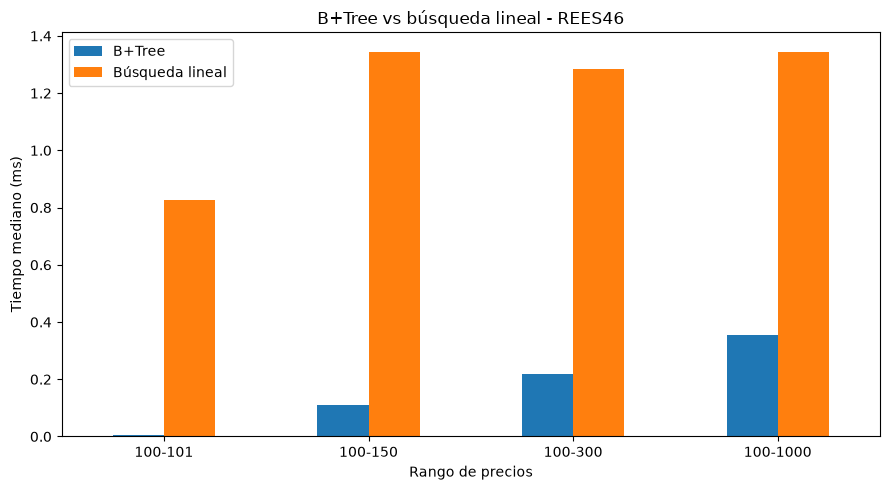

Resultados y gráfico guardados correctamente.


In [40]:

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = PROJECT_DIR / "figures"
results_dir = PROJECT_DIR / "results"

figures_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Guardar tabla de resultados
df_benchmark_bptree.to_csv(
    results_dir / "benchmark_bptree_vs_lineal.csv",
    index=False
)

# Crear gráfico comparativo
ax = df_benchmark_bptree.plot(
    x="rango",
    y=["bptree_ms", "lineal_ms"],
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("B+Tree vs búsqueda lineal - REES46")
ax.set_xlabel("Rango de precios")
ax.set_ylabel("Tiempo mediano (ms)")
ax.legend(["B+Tree", "Búsqueda lineal"])

plt.tight_layout()

plt.savefig(
    figures_dir / "benchmark_bptree_vs_lineal.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Resultados y gráfico guardados correctamente.")


## 22. Integración del pipeline: etapas 0 a 4

In [41]:
import importlib
import src.pipeline

# Recargar el módulo después de modificar pipeline.py
importlib.reload(src.pipeline)

# Importar la nueva función
from src.pipeline import run_priority_pipeline

print("¡Función importada correctamente!")

¡Función importada correctamente!


In [42]:

import importlib
import src.pipeline

importlib.reload(src.pipeline)

from src.pipeline import run_indexed_pipeline

# Ejecutar pipeline con 1,000 eventos
resultado_5_etapas = run_indexed_pipeline(
    events=df_events.head(1000).to_dict("records"),
    batch_size=200,
    cache_capacity=100,
    max_keys=32
)

catalog = resultado_5_etapas["catalog"]
index = resultado_5_etapas["price_index"]

# Consultar productos con precio entre 100 y 300
min_price = 100
max_price = 300

ids_bptree = index.range_search(
    min_price * 100,
    max_price * 100
)

# Comparar con búsqueda lineal del mismo catálogo
ids_linear = [
    product["product_id"]
    for product in catalog.products.values()
    if min_price * 100
    <= round(product["price"] * 100)
    <= max_price * 100
]

print("=== PIPELINE ETAPAS 0-4 ===")
print("Eventos recibidos:",
      resultado_5_etapas["metrics"]["received"])
print("Eventos procesados:",
      resultado_5_etapas["metrics"]["output"])
print("Productos en catálogo:", len(catalog))
print("Productos indexados:", len(index))
print("Interacciones CSR:",
      resultado_5_etapas["csr"]["matrix"].nnz)

print("\n=== CONSULTA B+TREE ===")
print("Rango de precios:", min_price, "-", max_price)
print("Resultados B+Tree:", len(ids_bptree))
print("Resultados lineales:", len(ids_linear))

assert len(index) == len(catalog)
assert len(ids_bptree) == len(ids_linear)
assert set(ids_bptree) == set(ids_linear)

print("Resultados coinciden: True")
print("\n¡Pipeline de etapas 0-4 validado!")


=== PIPELINE ETAPAS 0-4 ===
Eventos recibidos: 1000
Eventos procesados: 1000
Productos en catálogo: 534
Productos indexados: 534
Interacciones CSR: 701

=== CONSULTA B+TREE ===
Rango de precios: 100 - 300
Resultados B+Tree: 180
Resultados lineales: 180
Resultados coinciden: True

¡Pipeline de etapas 0-4 validado!


## 23. Persistencia de B+Tree

In [43]:

from pathlib import Path
from src.index_persistence import (
    save_bplus_tree,
    load_bplus_tree
)

# Ruta de almacenamiento
index_path = (
    PROJECT_DIR / "data" / "processed" / "price_index.pkl"
)

# Guardar índice generado por el pipeline
save_bplus_tree(
    resultado_5_etapas["price_index"],
    index_path
)

print("=== ÍNDICE GUARDADO ===")
print("Archivo:", index_path)
print("Existe:", index_path.exists())
print(f"Tamaño: {index_path.stat().st_size / 1024:.2f} KiB")

# Recuperar índice desde disco
recovered_index = load_bplus_tree(index_path)

# Verificar búsqueda después de recuperación
original_results = resultado_5_etapas[
    "price_index"
].range_search(10000, 30000)

recovered_results = recovered_index.range_search(
    10000, 30000
)

assert original_results == recovered_results
assert len(recovered_index) == len(
    resultado_5_etapas["price_index"]
)

print("\n=== VERIFICACIÓN ===")
print("Productos indexados:", len(recovered_index))
print("Resultados recuperados:", len(recovered_results))
print("Resultados idénticos:", True)

print("\n¡Persistencia de B+Tree validada!")


=== ÍNDICE GUARDADO ===
Archivo: c:\Users\bryan\Proyecto_EDA_UTEC\data\processed\price_index.pkl
Existe: True
Tamaño: 6.29 KiB

=== VERIFICACIÓN ===
Productos indexados: 534
Resultados recuperados: 180
Resultados idénticos: True

¡Persistencia de B+Tree validada!
